In [1]:
import jax
jax.config.update('jax_platform_name', 'cpu')
import os 
os.environ['CUDA_VISIBLE_DEVICES'] = ''

import sys 
sys.path.insert(1, '../')

import plotly.graph_objs as go
from plotly.offline import iplot

from jax import numpy as jnp
import numpy as np

from scipy.ndimage import gaussian_filter

import matplotlib.pyplot as plt

from tqdm.notebook import tqdm, trange

In [2]:
pm_seed = 4
i_list = range(128)
save_dirs = ['../../exp/vol_jwst%d_L_2_Lz_5_proj_gg_shape_sigma_0.25_lam_0.001/%d'%(pm_seed, i) for i in i_list]

wiener_recon = jnp.load('/srv/tmp/brandon/abacus/wiener_recon/wiener_jwst_4.npy').transpose(1, 2, 0)
ddpm_recon = jnp.load('/srv/tmp/brandon/abacus/wiener_recon/ddpm_jwst_4.npy')[:, 20:89, -69:] .transpose(1, 2, 0)
ddpm_samples = jnp.load('/srv/tmp/brandon/abacus/wiener_recon/ddpm_jwst_4_samples.npy')[:, :, 20:89, -69:].transpose(0, 2, 3, 1)
density_paths = [save_dir + '/density/density_500.p' for save_dir in save_dirs]

daps_recon = jnp.load('/srv/tmp/brandon/abacus/wiener_recon/ddpm_jwst_4_nops.npy')[:, 20:89, -69:] .transpose(1, 2, 0)
daps_samples = jnp.load('/srv/tmp/brandon/abacus/wiener_recon/ddpm_jwst_4_samples_nops.npy')[:, :, 20:89, -69:].transpose(0, 2, 3, 1)

dchi_tot = jnp.load('/srv/tmp/brandon/abacus/ps_theory/dchi_tot.npy')

res = 69
pixel_size = (27.2 / 2560) * np.pi / 180
pixel_size_radial = 164.5

CUDA backend failed to initialize: jaxlib/cuda/versions_helpers.cc:98: operation cuInit(0) failed: CUDA_ERROR_NO_DEVICE (Set TF_CPP_MIN_LOG_LEVEL=0 and rerun for more info.)


In [3]:
def mean_subtract(vol, axis=(0,1)): 
    return vol - jnp.mean(vol, axis=axis, keepdims=True)

densities = [mean_subtract(jnp.load(density_path).reshape(res, res, 20)) for density_path in density_paths]
densities_arr = jnp.array(densities)

density_gt = jnp.load(save_dirs[-1] + '/../density_gt.p').reshape(res, res, 20)

pws = jnp.load(save_dirs[0] + '/../pws.npy')
pws_ein = pws.reshape(-1, res, res, 20)

density_gt = mean_subtract(density_gt)
ddpm_recon = mean_subtract(ddpm_recon)
wiener_recon = mean_subtract(wiener_recon)

k_gt = jnp.einsum('nhwc,hwc->nhw', pws_ein, density_gt).mean(0)
k_nn = jnp.einsum('nhwc,mhwc->mnhw', pws_ein, densities_arr).mean(1)
k_dm_samples = jnp.einsum('nhwc,mhwc->mnhw', pws_ein, ddpm_samples).mean(1)
k_dm = jnp.einsum('nhwc,hwc->nhw', pws_ein, ddpm_recon).mean(0)
k_wiener = jnp.einsum('nhwc,hwc->nhw', pws_ein, wiener_recon).mean(0)

k_daps = jnp.einsum('nhwc,hwc->nhw', pws_ein, daps_recon).mean(0)
k_daps_samples = jnp.einsum('nhwc,mhwc->mnhw', pws_ein, daps_samples).mean(1)

In [4]:
print(k_nn.shape)
print(k_dm.shape)
print(k_wiener.shape)

(128, 69, 69)
(69, 69)
(69, 69)


In [5]:
def radial_profile(data):
  """
  Compute the radial profile of 2d image
  :param data: 2d image
  :return: radial profile
  """
  center = data.shape[0]/2
  y, x = jnp.indices((data.shape))
  r = jnp.sqrt((x - center)**2 + (y - center)**2)
  r = r.astype('int32')

  tbin = jnp.bincount(r.ravel(), data.ravel())
  nr = jnp.bincount(r.ravel())
  radialprofile = tbin / nr
  return radialprofile

def measure_power_spectrum(map_data, pixel_size):
  """
  measures power 2d data
  :param power: map (nxn)
  :param pixel_size: pixel_size (rad/pixel)
  :return: ell
  :return: power spectrum
  
  """
  N = map_data.shape[0]
  data_ft = jnp.fft.fftshift(jnp.fft.fft2(map_data)) / N
  nyquist = int(N/2)
  power_spectrum_1d =  radial_profile(jnp.real(data_ft*jnp.conj(data_ft)))[:nyquist] * (pixel_size)**2
  k = np.arange(power_spectrum_1d.shape[0])
  ell = 2. * np.pi * k / (pixel_size * N)
  return ell, power_spectrum_1d

measure_ps_batch = jax.vmap(measure_power_spectrum, in_axes=(0, None))

In [6]:
print(list(range(0)))

[]


In [7]:
def ps1d(map_data, pixel_size, return_ell = True):
    N = map_data.shape[-1]
    axes_reduce = list(range(len(map_data.shape)-1))
    
    data_ft = jnp.fft.fftshift(jnp.fft.fftn(map_data, axes=(-1,), norm='ortho'))
    nyquist = int(N/2)
    ps1d = jnp.real(data_ft * jnp.conj(data_ft))[..., :nyquist] * (pixel_size)**2
    
    if return_ell: 
        k = np.arange(ps1d.shape[-1])
        ell = 2. * np.pi * k / (pixel_size)
        return ell, jnp.mean(ps1d, axis=axes_reduce)
    else: 
        return jnp.mean(ps1d, axis=axes_reduce)

In [8]:
flat = k_gt.ravel()
topk = 20
# argpartition gets the topk unsorted; then sort those topk descending by value
idx_unsorted = np.argpartition(flat, -topk)[-topk:]
idx_sorted = idx_unsorted[np.argsort(flat[idx_unsorted])[::-1]]  # highest first
coords = np.array(np.unravel_index(idx_sorted, k_gt.shape)).T  # shape (topk, 2)
row = coords[:, 0].astype(np.intp)
col = coords[:, 1].astype(np.intp)

rand_key = jax.random.PRNGKey(0)

In [9]:
# white_noise_radial = jax.random.normal(rand_key, density_gt.shape) * density_gt[row, col, :].std()
# ell1d, ps1d_gt = ps1d(density_gt[row, col, :], pixel_size_radial)
# _, ps1d_noise = ps1d(white_noise_radial, pixel_size_radial)
# ps1d_neur = jnp.array([ps1d(densities_arr[i][row, col, :], pixel_size_radial, return_ell=False) for i in range(64)])
# ps1d_ddpm = jnp.array([ps1d(ddpm_samples[i][row, col, :], pixel_size_radial, return_ell=False) for i in range(64)])
# _, ps1d_wien = ps1d(wiener_recon, pixel_size_radial)

white_noise_radial = jax.random.normal(rand_key, density_gt.shape) * density_gt.std()
ell1d, ps1d_gt = ps1d(density_gt, pixel_size_radial)
_, ps1d_noise = ps1d(white_noise_radial, pixel_size_radial)
ps1d_neur = jnp.array([ps1d(densities_arr[i], pixel_size_radial, return_ell=False) for i in range(64)])
ps1d_ddpm = jnp.array([ps1d(ddpm_samples[i], pixel_size_radial, return_ell=False) for i in range(64)])
_, ps1d_wien = ps1d(wiener_recon, pixel_size_radial)

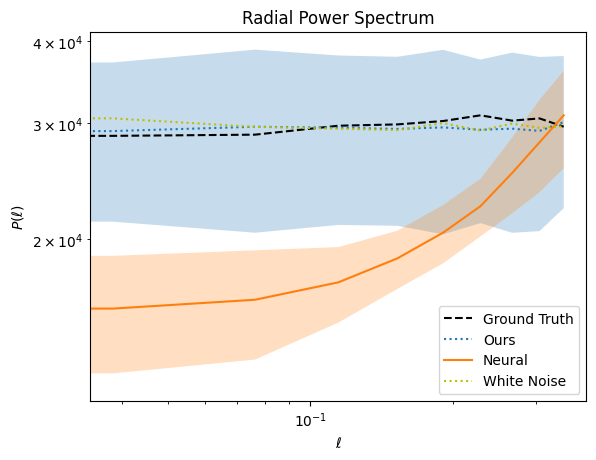

In [10]:
def hi_lo_mean(ps_arr): 
    ps_mean = ps_arr.mean(0)
    ps_std = ps_arr.std(0)
    ps_hi = ps_mean + 2*ps_std 
    ps_lo = ps_mean - 2*ps_std
    return ps_hi, ps_lo, ps_mean 

ps1d_neur_hi, ps1d_neur_lo, ps1d_neur_mean = hi_lo_mean(ps1d_neur)
ps1d_ddpm_hi, ps1d_ddpm_lo, ps1d_ddpm_mean = hi_lo_mean(ps1d_ddpm)

plt.loglog(ell1d, ps1d_gt, c='black', linestyle='dashed', label='Ground Truth')
plt.loglog(ell1d, ps1d_ddpm_mean, linestyle='dotted', label='Ours')
plt.fill_between(ell1d, ps1d_ddpm_lo, ps1d_ddpm_hi, alpha=0.25)
plt.loglog(ell1d, ps1d_neur_mean, label='Neural')
plt.fill_between(ell1d, ps1d_neur_lo, ps1d_neur_hi, alpha=0.25)
# plt.loglog(ell1d, ps1d_wien, label='Wiener')
plt.loglog(ell1d, ps1d_noise, c='y', linestyle='dotted', label='White Noise')

# plt.ylim([1e5, 5e6])
plt.title('Radial Power Spectrum')
plt.xlabel(r'$\ell$')
plt.ylabel(r'$P(\ell)$')

plt.legend()

plt.savefig('../jwst_figs/rad_power_spectra.pdf')
plt.show()

In [11]:
print(k_nn.shape)
print(k_dm_samples.shape)

ps_ddpms = []
ps_dapss = []
ps_neurs = []

for i in trange(64): 
    _, ps_ddpm = measure_power_spectrum(k_dm_samples[i], pixel_size)
    _, ps_daps = measure_power_spectrum(k_daps_samples[i], pixel_size)
    _, ps_neur = measure_power_spectrum(k_nn[i], pixel_size)

    ps_ddpms.append(ps_ddpm)
    ps_dapss.append(ps_daps)
    ps_neurs.append(ps_neur)


ps_ddpms = jnp.array(ps_ddpms)
ps_dapss = jnp.array(ps_dapss)
ps_neurs = jnp.array(ps_neurs)

ddpm_std = jnp.std(ps_ddpms, axis=0)
daps_std = jnp.std(ps_dapss, axis=0)
neur_std = jnp.std(ps_neurs, axis=0)

(128, 69, 69)
(128, 69, 69)


  0%|          | 0/64 [00:00<?, ?it/s]

In [12]:
# ell, ps_data = measure_power_spectrum(k_gt, pixel_size)
# ell, ps_neur = measure_power_spectrum(k_nn.mean(0), pixel_size)
# ell, ps_ddpm = measure_power_spectrum(k_dm, pixel_size)
# ell, ps_daps = measure_power_spectrum(k_dm, pixel_size)
# ell, ps_wien = measure_power_spectrum(k_wiener, pixel_size)

# lo_ddpm, hi_ddpm = ps_ddpm - 2*ddpm_std, ps_ddpm + 2*ddpm_std 
# lo_daps, hi_daps = ps_daps - 2*daps_std, ps_daps + 2*daps_std

# plt.figure(figsize=(12, 4))
# plt.subplot(1, 2, 1)
# plt.loglog(ell, ps_data, label='Ground Truth', c='black', linestyle='dashed')
# plt.loglog(ell, ps_ddpm, label='Ours', linestyle='dotted')
# plt.fill_between(ell, lo_ddpm, hi_ddpm, alpha=0.25)

# plt.loglog(ell, ps_daps, label='DAPS')
# plt.fill_between(ell, lo_daps, hi_daps, alpha=0.25)
# # plt.loglog(ell, ps_wien, label='Wiener')

# plt.ylabel(r'$C_\ell$')
# plt.xlabel(r'$\ell$');
# plt.title(r'$\kappa$ Angular $C_\ell$');
# plt.legend()

# plt.subplot(1, 2, 2)
# plt.semilogx(ell, (ps_ddpm - ps_data) / ps_data, label='Ours', linestyle='dotted')
# plt.fill_between(ell, (lo_ddpm - ps_data) / ps_data, (hi_ddpm - ps_data) / ps_data, alpha=0.25)

# plt.semilogx(ell, (ps_daps - ps_data) / ps_data, label='DAPS')
# plt.fill_between(ell, (lo_daps - ps_data) / ps_data, (hi_daps - ps_data) / ps_data, alpha=0.25)
# # plt.semilogx(ell, (ps_wien - ps_data) / ps_data, label='Wiener')
# plt.hlines([0.], ell[0], ell[-1], colors=['black'], linestyles=['--'], label='Ground Truth')
# plt.ylabel(r'$(C_\ell - C_\ell^{gt}) / C_\ell^{gt}$')
# plt.xlabel(r'$\ell$');
# plt.ylim([-1., 1.])
# plt.title(r'$\kappa$ Angular $C_\ell$ Residual');
# plt.legend()

# # plt.savefig('../jwst_figs/power_spectra.pdf', bbox_inches='tight')
# plt.show()

/tmp/ipykernel_2646724/2638252363.py:39: UserWarning:

Attempt to set non-positive xlim on a log-scaled axis will be ignored.

/tmp/ipykernel_2646724/2638252363.py:54: UserWarning:

Attempt to set non-positive xlim on a log-scaled axis will be ignored.



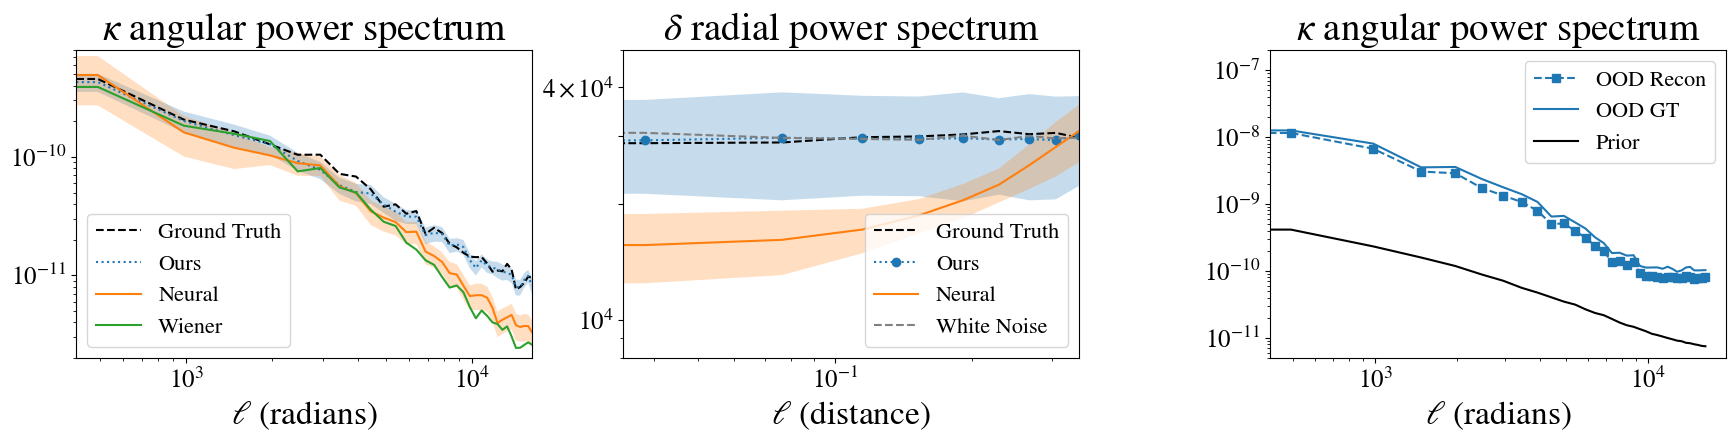

In [14]:
import matplotlib as mpl
import matplotlib.ticker as mticker

mpl.rcParams.update({
    "axes.unicode_minus": False,
    "font.family": "serif",
    "font.serif": ["STIXGeneral", "DejaVu Serif", "Times New Roman", "Times"],
    "mathtext.fontset": "stix",   # STIX math
    "xtick.labelsize": 18,
    "ytick.labelsize": 18,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

fontsize_legend = 16

ell, ps_data = measure_power_spectrum(k_gt, pixel_size)
ell, ps_neur = measure_power_spectrum(k_nn.mean(0), pixel_size)
ell, ps_ddpm = measure_power_spectrum(k_dm, pixel_size)
ell, ps_wien = measure_power_spectrum(k_wiener, pixel_size)

lo_ddpm, hi_ddpm = ps_ddpm - 2*ddpm_std, ps_ddpm + 2*ddpm_std 
lo_neur, hi_neur = ps_neur - 2*neur_std, ps_neur + 2*neur_std

plt.figure(figsize=(20, 4))
plt.subplot(1, 3, 1)
plt.loglog(ell, ps_data, label='Ground Truth', c='black', linestyle='dashed')
plt.loglog(ell, ps_ddpm, label='Ours', linestyle='dotted')
plt.fill_between(ell, lo_ddpm, hi_ddpm, alpha=0.25)

plt.loglog(ell, ps_neur, label='Neural')
plt.fill_between(ell, lo_neur, hi_neur, alpha=0.25)
plt.loglog(ell, ps_wien, label='Wiener')

# plt.ylabel(r'$C_\ell$', fontsize=24)
plt.xlabel(r'$\ell$ (radians)', fontsize=24)
plt.title(r'$\kappa$ angular power spectrum', fontsize=28);
plt.legend(fontsize=fontsize_legend, loc='lower left')
plt.xlim([ell.min(), ell.max()])
plt.ylim([2e-12, 8e-10])

plt.subplot(1, 3, 2)

ps1d_neur_hi, ps1d_neur_lo, ps1d_neur_mean = hi_lo_mean(ps1d_neur)
ps1d_ddpm_hi, ps1d_ddpm_lo, ps1d_ddpm_mean = hi_lo_mean(ps1d_ddpm)

plt.loglog(ell1d, ps1d_gt, c='black', linestyle='dashed', label='Ground Truth')
plt.loglog(ell1d, ps1d_ddpm_mean, 'o', linestyle='dotted', label='Ours')
plt.fill_between(ell1d, ps1d_ddpm_lo, ps1d_ddpm_hi, alpha=0.25)
plt.loglog(ell1d, ps1d_neur_mean, label='Neural')
plt.fill_between(ell1d, ps1d_neur_lo, ps1d_neur_hi, alpha=0.25)
# plt.loglog(ell1d, ps1d_wien, label='Wiener')
plt.loglog(ell1d, ps1d_noise, c='gray', linestyle='--', label='White Noise')
plt.xlim([ell1d.min(), ell1d.max()])

ax = plt.gca()
# Lock the range and ticks you want
ax.set_yscale('log')
ax.set_ylim(8e3, 5e4)
ticks = [1e4, 2e4, 3e4, 4e4]
ax.set_yticks(ticks)
ax.yaxis.set_minor_formatter(mticker.NullFormatter())

# Custom formatter: show "10^4" and "4×10^4" (not 10^4.6)
def sci_label(y):
    if y <= 0:
        return ""
    e = int(np.floor(np.log10(y)))
    m = y / (10**e)
    # snap mantissa to a nice integer if it's very close (e.g., 3.999999 -> 4)
    m_round = np.round(m)
    if np.isclose(m, m_round, atol=1e-9):
        m = int(m_round)
    return rf"$10^{e}$" if m == 1 else rf"${m}\times10^{e}$"

def label_first_last(y, pos):
    return sci_label(y) if (np.isclose(y, ticks[0]) or np.isclose(y, ticks[-1])) else ""

ax.yaxis.set_major_formatter(mticker.FuncFormatter(label_first_last))

# plt.ylim([8e3, 5e4])
plt.title('$\delta$ radial power spectrum', fontsize=28)
# plt.yticks(ticks=[1e4, 8e4], labels=[1e4, 8e4])
plt.xlabel(r'$\ell$ (distance)', fontsize=24)
# plt.ylabel(r'$C_\ell$', fontsize=24, labelpad=-40)

plt.legend(fontsize=fontsize_legend, loc='lower right')
plt.subplots_adjust(hspace=0.35)  



pws = np.load('/srv/tmp/brandon/abacus/pws/pws_69.npy')
samples_uncon = np.load('/srv/tmp/brandon/abacus/wiener_recon/ddpm_jwst_uncond_samples.npy')[..., :69, :69]
samples_jwst4 = np.load('/srv/tmp/brandon/abacus/wiener_recon/ddpm_jwst_4_samples.npy')[..., 20:89, -69:]
samples__c009 = np.load('/srv/tmp/brandon/abacus/wiener_recon/ddpm_jwst_c009_samples.npy')[..., 44:113, 25:94]

od_gt__c009 = mean_subtract(jnp.array([jnp.load(f'/srv/tmp/brandon/abacus/lp_dataset_patched_c009/{lp:02d}/ph000_lc1_026.npy') for lp in range(20)]).squeeze()[:, 44:113, 25:94])
od_gt_jwst4 = mean_subtract(jnp.array([jnp.load(f'/srv/tmp/brandon/abacus/lp_dataset_patched/{lp:02d}/ph000_lc1_040.npy') for lp in range(20)]).squeeze()[:, 20:89, -69:])

def proj_kappa(samples, pws): 
    return jnp.einsum('nchw,mchw->nmhw', samples, pws).mean(1)

k_uncon = proj_kappa(samples_uncon, pws)
k_jwst4 = proj_kappa(samples_jwst4, pws)
k__c009 = proj_kappa(samples__c009, pws)

k_jwst4_gt = proj_kappa(od_gt_jwst4[None, :], pws)[0]
k__c009_gt = proj_kappa(od_gt__c009[None, :], pws)[0]

ell, ps_uncon = measure_ps_batch(k_uncon, pixel_size)
_,   ps_jwst4 = measure_ps_batch(k_jwst4, pixel_size)
_,   ps__c009 = measure_ps_batch(k__c009, pixel_size)

_, ps_jwst4_gt = measure_power_spectrum(k_jwst4_gt, pixel_size)
_, ps__c009_gt = measure_power_spectrum(k__c009_gt, pixel_size)

ell = ell[0]
colors = mpl.color_sequences['tab10']

ax3 = plt.subplot(1, 3, 3)
# plt.loglog(ell, ps_jwst4.mean(0), 'o--', color='red', label='In-Dist Recon')
# plt.loglog(ell, ps_jwst4_gt, color='red', label='In-Dist GT')

plt.loglog(ell, ps__c009.mean(0), 's--', color=colors[0], label='OOD Recon')
plt.loglog(ell, ps__c009_gt, color=colors[0], label='OOD GT')

plt.loglog(ell, ps_uncon.mean(0), 'black', label='Prior')

plt.legend(fontsize=fontsize_legend)

# plt.ylabel(r'$C_\ell$', fontsize=24)
plt.xlabel(r'$\ell$ (radians)', fontsize=24)
plt.title(r'$\kappa$ angular power spectrum', fontsize=28)
plt.ylim([5e-12, 2e-7])

box = ax3.get_position()
ax3.set_position([box.x0 + 0.05, box.y0, box.width, box.height])  # 0.05 is tunable

plt.savefig('power_spectra_3_2.svg' , bbox_inches='tight')
plt.show()


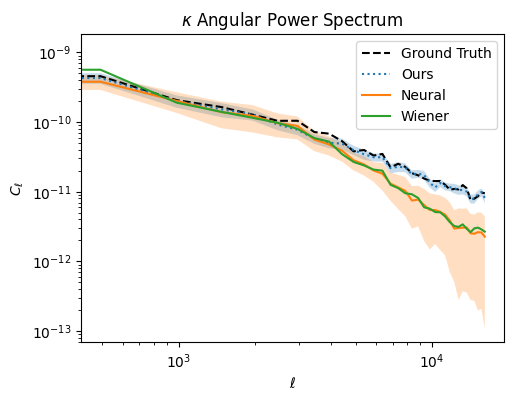

In [16]:
ell, ps_data = measure_power_spectrum(k_gt, pixel_size)
ell, ps_neur = measure_power_spectrum(k_nn.mean(0), pixel_size)
ell, ps_ddpm = measure_power_spectrum(k_dm, pixel_size)
ell, ps_wien = measure_power_spectrum(k_wiener, pixel_size)

lo_ddpm, hi_ddpm = ps_ddpm - 2*ddpm_std, ps_ddpm + 2*ddpm_std 
lo_neur, hi_neur = ps_neur - 2*neur_std, ps_neur + 2*neur_std

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.loglog(ell, ps_data, label='Ground Truth', c='black', linestyle='dashed')
plt.loglog(ell, ps_ddpm, label='Ours', linestyle='dotted')
plt.fill_between(ell, lo_ddpm, hi_ddpm, alpha=0.25)

plt.loglog(ell, ps_neur, label='Neural')
plt.fill_between(ell, lo_neur, hi_neur, alpha=0.25)
plt.loglog(ell, ps_wien, label='Wiener')

plt.ylabel(r'$C_\ell$')
plt.xlabel(r'$\ell$');
plt.title(r'$\kappa$ Angular Power Spectrum');
plt.legend()

plt.savefig('power_spectra_1.pdf')
plt.show()

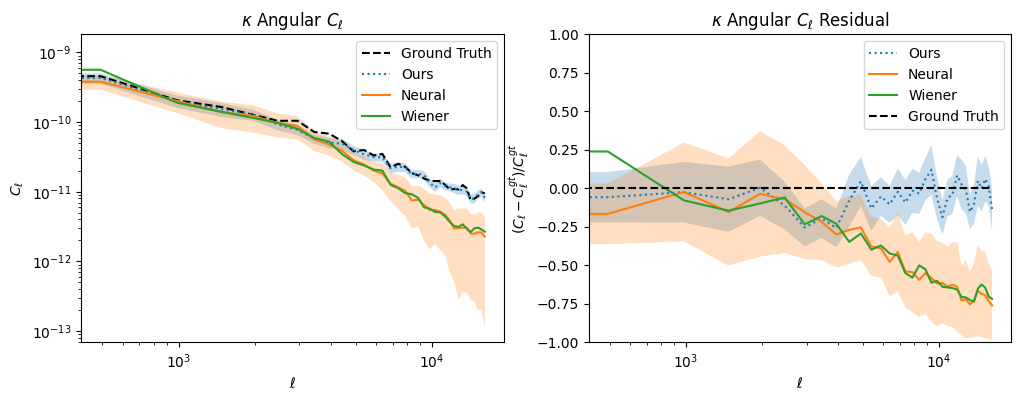

In [17]:
ell, ps_data = measure_power_spectrum(k_gt, pixel_size)
ell, ps_neur = measure_power_spectrum(k_nn.mean(0), pixel_size)
ell, ps_ddpm = measure_power_spectrum(k_dm, pixel_size)
ell, ps_wien = measure_power_spectrum(k_wiener, pixel_size)

lo_ddpm, hi_ddpm = ps_ddpm - 2*ddpm_std, ps_ddpm + 2*ddpm_std 
lo_neur, hi_neur = ps_neur - 2*neur_std, ps_neur + 2*neur_std

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.loglog(ell, ps_data, label='Ground Truth', c='black', linestyle='dashed')
plt.loglog(ell, ps_ddpm, label='Ours', linestyle='dotted')
plt.fill_between(ell, lo_ddpm, hi_ddpm, alpha=0.25)

plt.loglog(ell, ps_neur, label='Neural')
plt.fill_between(ell, lo_neur, hi_neur, alpha=0.25)
plt.loglog(ell, ps_wien, label='Wiener')

plt.ylabel(r'$C_\ell$')
plt.xlabel(r'$\ell$');
plt.title(r'$\kappa$ Angular $C_\ell$');
plt.legend()

plt.subplot(1, 2, 2)
plt.semilogx(ell, (ps_ddpm - ps_data) / ps_data, label='Ours', linestyle='dotted')
plt.fill_between(ell, (lo_ddpm - ps_data) / ps_data, (hi_ddpm - ps_data) / ps_data, alpha=0.25)

plt.semilogx(ell, (ps_neur - ps_data) / ps_data, label='Neural')
plt.fill_between(ell, (lo_neur - ps_data) / ps_data, (hi_neur - ps_data) / ps_data, alpha=0.25)
plt.semilogx(ell, (ps_wien - ps_data) / ps_data, label='Wiener')
plt.hlines([0.], ell[0], ell[-1], colors=['black'], linestyles=['--'], label='Ground Truth')
plt.ylabel(r'$(C_\ell - C_\ell^{gt}) / C_\ell^{gt}$')
plt.xlabel(r'$\ell$');
plt.ylim([-1., 1.])
plt.title(r'$\kappa$ Angular $C_\ell$ Residual');
plt.legend()

plt.savefig('../jwst_figs/power_spectra.pdf', bbox_inches='tight')
plt.show()

In [18]:
ell_big = np.load('/srv/tmp/brandon/abacus/ps_theory/ell.npy')
ps_theories = np.load('/srv/tmp/brandon/abacus/ps_theory/ps_theories.npy')
dchi = np.load('/srv/tmp/brandon/abacus/ps_theory/dchi_tot.npy')
z_list = np.load('/srv/tmp/brandon/abacus/ps_theory/z_list.npy')

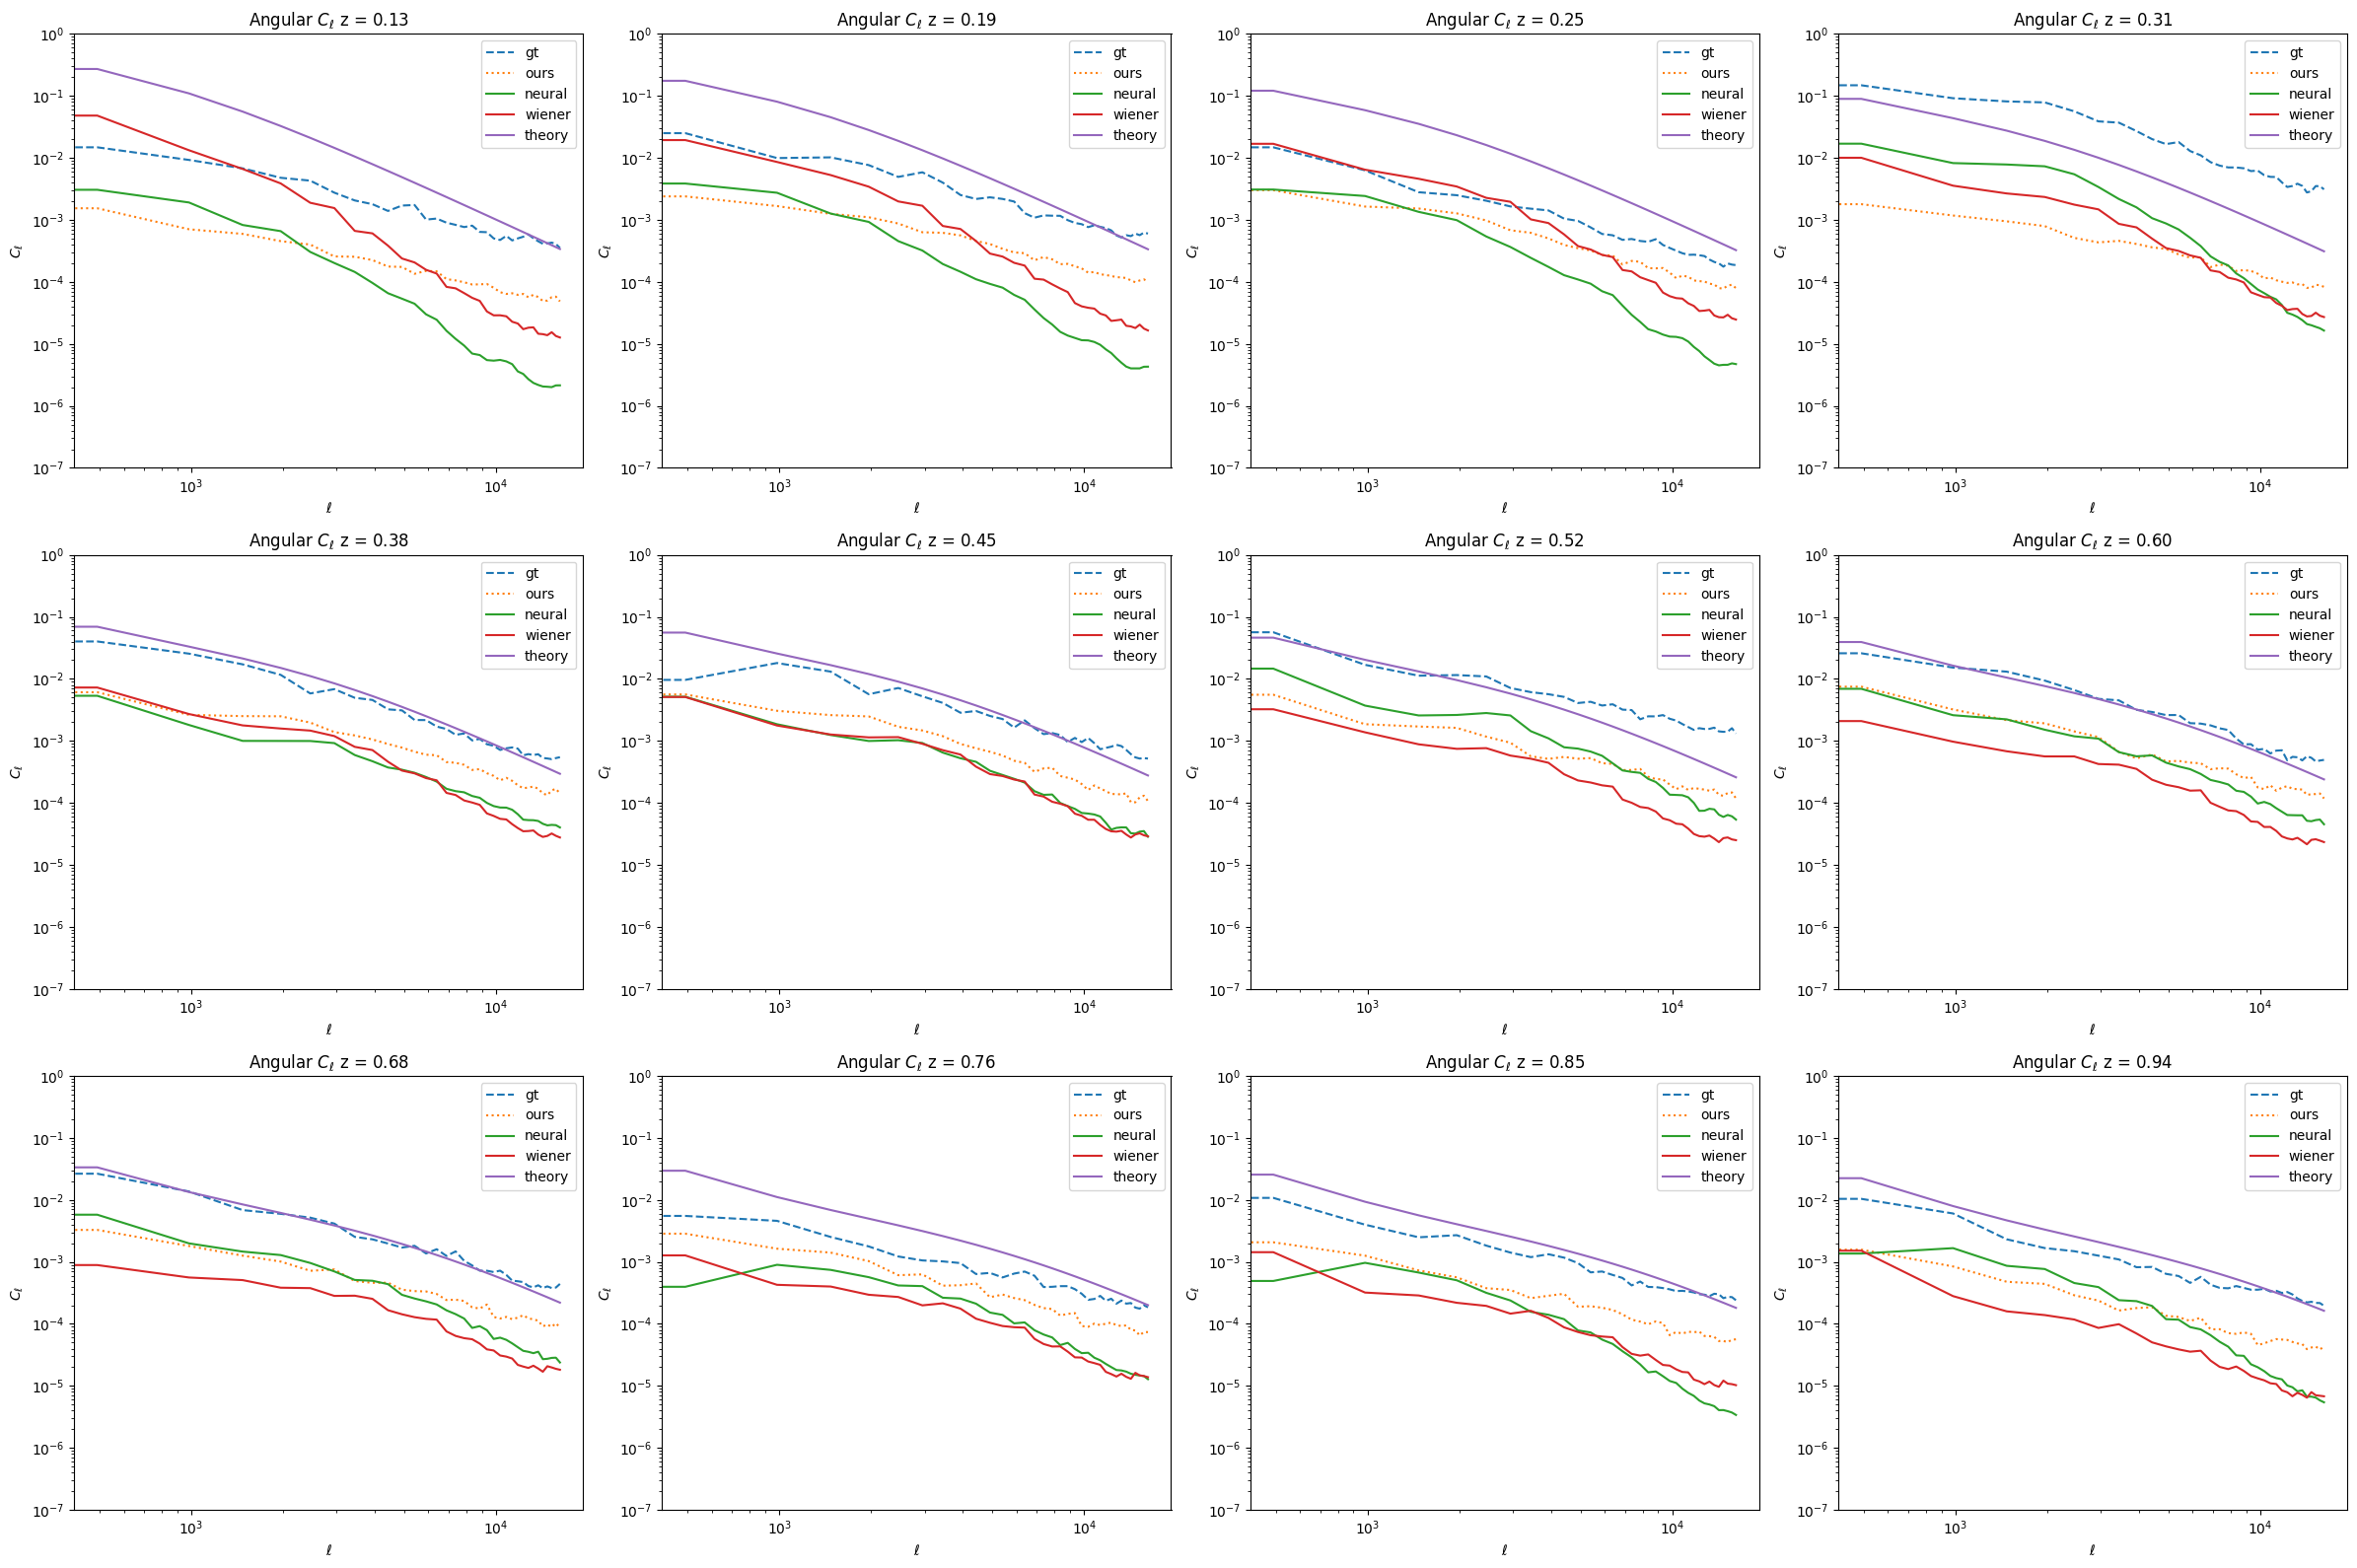

In [19]:
plt.figure(figsize=(24, 16))

for i in range(12):
    plt.subplot(3, 4, i+1)

    ell, ps_data = measure_power_spectrum(density_gt[..., i] * dchi[i], pixel_size)
    ell, ps_neur = measure_power_spectrum(densities_arr.mean(0)[..., i] * dchi[i], pixel_size)
    ell, ps_ddpm = measure_power_spectrum(ddpm_recon[..., i] * dchi[i], pixel_size)
    # ell, ps_ddpm = measure_power_spectrum(ddpm_samples[0, ..., i] * dchi[i], pixel_size)
    ell, ps_wien = measure_power_spectrum(wiener_recon[..., i] * dchi[i], pixel_size)

    ps_theory = jnp.interp(ell, ell_big, ps_theories[i])

    plt.loglog(ell, ps_data, label='gt', linestyle='dashed')
    plt.loglog(ell, ps_ddpm, label='ours', linestyle='dotted')
    plt.loglog(ell, ps_neur, label='neural')
    plt.loglog(ell, ps_wien, label='wiener')

    plt.loglog(ell, ps_theory, label='theory')

    plt.ylim([1e-7, 1])
    plt.ylabel(r'$C_\ell$')
    plt.xlabel(r'$\ell$');
    plt.title(r'Angular $C_\ell$ z = ' + f'{z_list[i]:.2f}');
    plt.legend()

plt.tight_layout()
plt.show()

In [20]:
plt.figure(figsize=(24, 16))

for i in range(12):
    plt.subplot(3, 4, i+1)

    ell, ps_data = measure_power_spectrum(density_gt[..., i] * dchi[i], pixel_size)
    ell, ps_neur = measure_power_spectrum(densities_arr.mean(0)[..., i] * dchi[i], pixel_size)
    ell, ps_ddpm = measure_power_spectrum(ddpm_samples[0, ..., i] * dchi[i], pixel_size)
    ell, ps_wien = measure_power_spectrum(wiener_recon[..., i] * dchi[i], pixel_size)

    ps_theory = jnp.interp(ell, ell_big, ps_theories[i])

    plt.loglog(ell, ps_data, label='gt', linestyle='dashed')
    plt.loglog(ell, ps_ddpm, label='ours', linestyle='dotted')
    plt.loglog(ell, ps_neur, label='neural')
    plt.loglog(ell, ps_wien, label='wiener')

    plt.loglog(ell, ps_theory, label='theory')

    plt.ylim([1e-7, 1])
    plt.ylabel(r'$C_\ell$')
    plt.xlabel(r'$\ell$');
    plt.title(r'Angular $C_\ell$ z = ' + f'{z_list[i]:.2f}');
    plt.legend()

plt.tight_layout()
plt.show()

KeyboardInterrupt: 